<a href="https://colab.research.google.com/github/patrickkrussell/data_science_and_analytics/blob/main/Predicting%20online%20purchase/Online_Retail_II_UCI_predicted_purchases.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

# URL to the Online Retail II Excel dataset directly from the UCI Machine Learning Repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00502/online_retail_II.xlsx'

print("Downloading and loading Online Retail II dataset directly from UCI Repository... This might take a minute.")

# Read the first sheet (Year 2009-2010)
df = pd.read_excel(url, sheet_name='Year 2009-2010')

print("Dataset loaded successfully!")
display(df.head(25))

Dataset loaded successfully!


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [3]:
print(df["Invoice"].value_counts)

<bound method IndexOpsMixin.value_counts of 0         489434
1         489434
2         489434
3         489434
4         489434
           ...  
525456    538171
525457    538171
525458    538171
525459    538171
525460    538171
Name: Invoice, Length: 525461, dtype: object>


In [4]:
# Check the data types and basic info of the DataFrame
print("=== DataFrame Info ===")
df.info()

# Count missing values in each column
print("\n=== Missing Values Per Column ===")
missing_values = df.isnull().sum()
display(missing_values)

=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB

=== Missing Values Per Column ===


,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


In [5]:
# Filter rows where 'Customer ID' is null
missing_customer_df = df[df['Customer ID'].isnull()]

# Display the total count and a sample of these rows
print(f"Total rows with missing Customer ID: {len(missing_customer_df)}")
display(missing_customer_df.head(20))

Total rows with missing Customer ID: 107927


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


In [6]:
# Drop rows where 'Customer ID' is missing
print(f"Original shape: {df.shape}")
df = df.dropna(subset=['Customer ID'])
print(f"Shape after dropping missing Customer IDs: {df.shape}")

# Confirm that no null Customer IDs remain
print(f"Remaining missing Customer IDs: {df['Customer ID'].isnull().sum()}")
display(df.head())

Original shape: (525461, 8)
Shape after dropping missing Customer IDs: (417534, 8)
Remaining missing Customer IDs: 0


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [7]:
# Drop rows where 'Description' is missing
print(f"Shape before dropping missing Descriptions: {df.shape}")
df = df.dropna(subset=['Description'])
print(f"Shape after dropping missing Descriptions: {df.shape}")

# Confirm remaining missing Descriptions
print(f"Remaining missing Descriptions: {df['Description'].isnull().sum()}")

Shape before dropping missing Descriptions: (417534, 8)
Shape after dropping missing Descriptions: (417534, 8)
Remaining missing Descriptions: 0


In [8]:
print(min(df['Quantity']), max(df['Quantity']))

-9360 19152


In [9]:
print(min(df['Price']), max(df['Price']))

0.0 25111.09


In [10]:
# Filter the DataFrame to keep only records with negative quantities
negative_quantity_df = df[df['Quantity'] < 0]

# Display the count and the first few rows of this new DataFrame
print(f"Total records with negative quantity: {len(negative_quantity_df)}")
display(negative_quantity_df.head())

Total records with negative quantity: 9839


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [11]:
# Check if all invoices with negative quantities start with the letter 'C'
invoices_with_c = negative_quantity_df['Invoice'].astype(str).str.startswith('C')

# Calculate how many start with 'C' versus those that do not
starts_with_c_count = invoices_with_c.sum()
total_negatives = len(negative_quantity_df)

print(f"Total negative quantity records: {total_negatives}")
print(f"Records starting with 'C': {starts_with_c_count}")
print(f"Records NOT starting with 'C': {total_negatives - starts_with_c_count}")

# If there are any exceptions, display them
if total_negatives != starts_with_c_count:
    print("\nExamples of negative quantity invoices NOT starting with 'C':")
    display(negative_quantity_df[~invoices_with_c].head())

Total negative quantity records: 9839
Records starting with 'C': 9839
Records NOT starting with 'C': 0


In [12]:
# Calculate records with negative quantity
negative_quantity_count = (df['Quantity'] < 0).sum()

# Calculate records with invoice starting with 'C'
c_invoice_count = df['Invoice'].astype(str).str.startswith('C').sum()

print(f"Number of records with negative quantity: {negative_quantity_count}")
print(f"Number of records with 'C' in front of invoice: {c_invoice_count}")

Number of records with negative quantity: 9839
Number of records with 'C' in front of invoice: 9839


In [13]:
# Remove records with a negative quantity
print(f"Shape before filtering: {df.shape}")
df = df[df['Quantity'] >= 0]
print(f"Shape after filtering out negative quantities: {df.shape}")

# Confirm no negative quantities remain
print(f"Remaining negative quantity records: {(df['Quantity'] < 0).sum()}")

Shape before filtering: (417534, 8)
Shape after filtering out negative quantities: (407695, 8)
Remaining negative quantity records: 0


In [14]:
# Calculate the 75th percentile (upper quartile) of Price
q3_price = df['Price'].quantile(0.75)
print(f"The upper quartile (75th percentile) of Price is: {q3_price}")

# Filter and display records in the upper quartile
upper_quartile_df = df[df['Price'] >= q3_price].sort_values(by='Price', ascending=False)
print(f"Total records in the upper quartile of price: {len(upper_quartile_df)}")
display(upper_quartile_df.head(20))

print(upper_quartile_df['Description'].value_counts())

The upper quartile (75th percentile) of Price is: 3.75
Total records in the upper quartile of price: 109934


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom
358639,524159,M,Manual,1,2010-09-27 16:12:00,10468.80,14063.0,United Kingdom
74356,496115,M,Manual,1,2010-01-29 11:04:00,8985.60,17949.0,United Kingdom
129987,501768,M,Manual,1,2010-03-19 11:45:00,6958.17,15760.0,Norway
129903,501766,M,Manual,1,2010-03-19 11:35:00,6958.17,15760.0,Norway
288706,517483,M,Manual,1,2010-07-29 12:29:00,3610.50,12737.0,France
358670,524162,M,Manual,1,2010-09-27 16:18:00,2769.90,14063.0,United Kingdom
418886,529356,M,Manual,1,2010-10-28 09:44:00,2736.16,14156.0,EIRE
394037,527258,M,Manual,1,2010-10-15 12:40:00,2667.88,15202.0,United Kingdom
374485,525498,M,Manual,1,2010-10-05 16:47:00,2545.85,14156.0,EIRE


Description
REGENCY CAKESTAND 3 TIER               1705
HOME BUILDING BLOCK WORD               1219
LOVE BUILDING BLOCK WORD                987
BAKING SET 9 PIECE RETROSPOT            897
SCOTTIE DOG HOT WATER BOTTLE            894
                                       ... 
GLASS AND PAINTED BEADS BRACELET OL       1
SET OF 4 CAROUSEL PLACEMATS               1
WHITE VINTAGE CRYSTAL EARRINGS            1
S/6 CHRISTMAS TREE PLACE SETTING          1
JADE GREEN PAIR ENAMEL HAIR SLIDES        1
Name: count, Length: 1500, dtype: int64


In [15]:
# Filter and display records above $100
above_100_df = df[df['Price'] >= 100].sort_values(by='Price', ascending=False)
print(f"Total records above $100: {len(above_100_df)}")
display(above_100_df.head(20))

print(above_100_df['Description'].value_counts())

Total records above $100: 175


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom
358639,524159,M,Manual,1,2010-09-27 16:12:00,10468.80,14063.0,United Kingdom
74356,496115,M,Manual,1,2010-01-29 11:04:00,8985.60,17949.0,United Kingdom
129987,501768,M,Manual,1,2010-03-19 11:45:00,6958.17,15760.0,Norway
129903,501766,M,Manual,1,2010-03-19 11:35:00,6958.17,15760.0,Norway
288706,517483,M,Manual,1,2010-07-29 12:29:00,3610.50,12737.0,France
358670,524162,M,Manual,1,2010-09-27 16:18:00,2769.90,14063.0,United Kingdom
418886,529356,M,Manual,1,2010-10-28 09:44:00,2736.16,14156.0,EIRE
394037,527258,M,Manual,1,2010-10-15 12:40:00,2667.88,15202.0,United Kingdom
374485,525498,M,Manual,1,2010-10-05 16:47:00,2545.85,14156.0,EIRE


Description
Manual                                 66
POSTAGE                                22
VINTAGE BLUE KITCHEN CABINET           17
VINTAGE RED KITCHEN CABINET            15
FRENCH STYLE WALL DRESSER              12
Adjustment by john on 26/01/2010 16     9
GIANT SEVENTEEN DRAWER SIDEBOARD        6
Adjustment by john on 26/01/2010 17     5
REGENCY MIRROR WITH SHUTTERS            5
RUSTIC  SEVENTEEN DRAWER SIDEBOARD      5
CHEST NATURAL WOOD 20 DRAWERS           5
Adjustment by Peter on Jun 25 2010      2
CARRIAGE                                2
ANT WHITE SWEETHEART TABLE W 3 DRAW     2
BLUE KASHMIRI COFFEE TABLE              1
Discount                                1
Name: count, dtype: int64


In [16]:
df_manual = df[df['Description'] == "Discount"]
print(df_manual, df_manual.shape)

       Invoice StockCode Description  Quantity         InvoiceDate   Price  \
160443  504700         D    Discount         1 2010-04-15 18:08:00   57.63   
212633  509979         D    Discount         1 2010-05-26 14:07:00  101.99   
312285  519808         D    Discount       192 2010-08-20 12:50:00    1.00   
494226  535657         D    Discount         1 2010-11-28 11:20:00   13.98   
501237  536158         D    Discount         1 2010-11-30 11:57:00   32.29   

        Customer ID         Country  
160443      17032.0  United Kingdom  
212633      12843.0  United Kingdom  
312285      16422.0  United Kingdom  
494226      14527.0  United Kingdom  
501237      13634.0  United Kingdom   (5, 8)


In [17]:
# Remove records where the Description is 'Manual'
print(f"Shape before removing Manual records: {df.shape}")
df = df[df['Description'] != 'Manual']
print(f"Shape after removing Manual records: {df.shape}")

# Confirm that no Manual descriptions remain
remaining_manual = (df['Description'] == 'Manual').sum()
print(f"Remaining 'Manual' records: {remaining_manual}")

Shape before removing Manual records: (407695, 8)
Shape after removing Manual records: (407269, 8)
Remaining 'Manual' records: 0


In [18]:
# Clean the descriptions
print(f"Shape before filtering: {df.shape}")

# Filter out 'Manual', 'Discount' (exact, case-insensitive checks)
# And filter out descriptions starting with 'Adjustment' (case-insensitive)
descr_lower = df['Description'].astype(str).str.lower().str.strip()

mask_to_remove = (
    (descr_lower == 'manual') |
    (descr_lower == 'discount') |
    (descr_lower.str.startswith('adjustment') |
    (descr_lower == "postage") |
     descr_lower.str.startswith("pads"))
)

df = df[~mask_to_remove]

print(f"Shape after filtering: {df.shape}")
print(f"Removed {mask_to_remove.sum()} records.")

Shape before filtering: (407269, 8)
Shape after filtering: (406477, 8)
Removed 792 records.


In [19]:
# Create a new DataFrame with unique products (using StockCode & Description) and their prices
df_products_prices = df[['StockCode', 'Description', 'Price']].drop_duplicates().sort_values(by = 'Price', ascending = True)

print(f"Unique combinations of products and prices: {df_products_prices.shape[0]}")
display(df_products_prices.head(20))

Unique combinations of products and prices: 8257


,StockCode,Description,Price
512240,22841,ROUND CAKE TIN VINTAGE GREEN,0.0
89084,TEST001,This is a test product.,0.0
32916,85042,ANTIQUE LILY FAIRY LIGHTS,0.0
248583,22423,REGENCY CAKESTAND 3 TIER,0.0
471775,22846,BREAD BIN DINER STYLE RED,0.0
471776,22845,VINTAGE CREAM CAT FOOD CONTAINER,0.0
47126,79320,FLAMINGO LIGHTS,0.0
111348,21662,VINTAGE GLASS COFFEE CADDY,0.0
400047,22121,NOEL WOODEN BLOCK LETTERS,0.0
40101,21143,ANTIQUE GLASS HEART DECORATION,0.0


In [20]:
print(df[df['Price'] == 0.0])

       Invoice StockCode                        Description  Quantity  \
4674    489825     22076                 6 RIBBONS EMPIRE          12   
6781    489998     48185                DOOR MAT FAIRY CAKE         2   
18738   490961     22065     CHRISTMAS PUDDING TRINKET POT          1   
18739   490961     22142       CHRISTMAS CRAFT WHITE FAIRY         12   
32916   492079     85042          ANTIQUE LILY FAIRY LIGHTS         8   
40101   492760     21143    ANTIQUE GLASS HEART DECORATION         12   
47126   493761     79320                    FLAMINGO LIGHTS        24   
48342   493899     22355        CHARLOTTE BAG , SUKI DESIGN        10   
57619   494607     21533          RETRO SPOT LARGE MILK JUG        12   
89084   497819   TEST001            This is a test product.         5   
89180   497843   TEST001            This is a test product.         5   
111348  500073     21662         VINTAGE GLASS COFFEE CADDY         1   
149201  503585     22459       CAST IRON HOOK GARDE

In [21]:
# Remove records where price is 0.0
print(f"Shape before filtering: {df.shape}")
df = df[df['Price'] != 0.0]
print(f"Shape after filtering out 0.0 price records: {df.shape}")

# Confirm that no 0.0 prices remain
remaining_zero_prices = (df['Price'] == 0.0).sum()
print(f"Remaining records with price 0.0: {remaining_zero_prices}")


Shape before filtering: (406477, 8)
Shape after filtering out 0.0 price records: (406447, 8)
Remaining records with price 0.0: 0


In [22]:
print(df[df["StockCode"] == "TEST001"])

print(f"Shape before filtering: {df.shape}")
df = df[df['StockCode'] != "TEST001"]
print(f"Shape after filtering out TEST001 records: {df.shape}")

# Confirm that no 0.0 prices remain
remaining_zero_prices = (df['StockCode'] == "TEST001").sum()
print(f"Remaining records with TEST001: {remaining_zero_prices}")


       Invoice StockCode              Description  Quantity  \
27994   491725   TEST001  This is a test product.        10   
28251   491742   TEST001  This is a test product.         5   
28254   491744   TEST001  This is a test product.         5   
39398   492718   TEST001  This is a test product.         5   
45228   493410   TEST001  This is a test product.         5   
45230   493412   TEST001  This is a test product.         5   
56117   494450   TEST001  This is a test product.         5   
66084   495295   TEST001  This is a test product.         5   
156017  504188   TEST001  This is a test product.         5   

               InvoiceDate  Price  Customer ID         Country  
27994  2009-12-14 08:34:00    4.5      12346.0  United Kingdom  
28251  2009-12-14 11:00:00    4.5      12346.0  United Kingdom  
28254  2009-12-14 11:02:00    4.5      12346.0  United Kingdom  
39398  2009-12-18 10:47:00    4.5      12346.0  United Kingdom  
45228  2010-01-04 09:24:00    4.5      12346

In [23]:
print(df["Quantity"].min(), df["Quantity"].max())

q3_quant = df['Quantity'].quantile(0.75)
print(f"The upper quartile (75th percentile) of Quantity is: {q3_quant}")

# Filter and display records in the upper quartile
upper_quartile_df = df[df['Quantity'] >= q3_quant].sort_values(by='Quantity', ascending=False)
print(f"Total records in the upper quartile of quanity: {len(upper_quartile_df)}")
display(upper_quartile_df.head(20))

#print(upper_quartile_df['Description'].value_counts())

1 19152
The upper quartile (75th percentile) of Quantity is: 12.0
Total records in the upper quartile of quanity: 123713


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
93677,498152,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,9456,2010-02-17 10:51:00,0.30,13902.0,Denmark


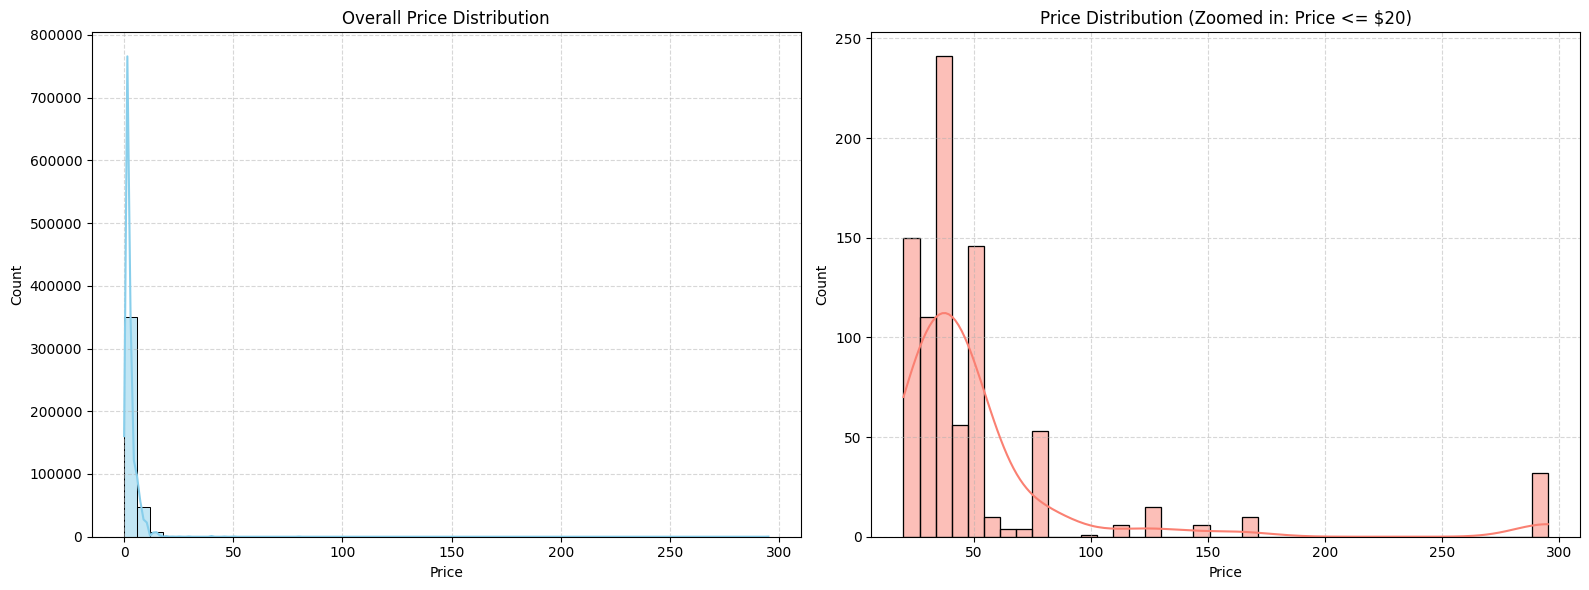

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with two subplots: overall distribution and zoomed-in distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Overall Price Distribution (including potential outliers)
sns.histplot(df['Price'], bins=50, ax=axes[0], kde=True, color='skyblue')
axes[0].set_title('Overall Price Distribution')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Count')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Zoomed-in Price Distribution (prices <= $20 to see the bulk of the data)
bulk_prices = df[df['Price'] >= 20]['Price']
sns.histplot(bulk_prices, bins=40, ax=axes[1], kde=True, color='salmon')
axes[1].set_title('Price Distribution (Zoomed in: Price <= $20)')
axes[1].set_xlabel('Price')
axes[1].set_ylabel('Count')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [25]:
print(df.sort_values(by='Price', ascending=False))


       Invoice StockCode                        Description  Quantity  \
317599  520350     22655        VINTAGE RED KITCHEN CABINET         1   
283393  516949     22656       VINTAGE BLUE KITCHEN CABINET         1   
292603  517909     22655        VINTAGE RED KITCHEN CABINET         1   
292665  517930     22656       VINTAGE BLUE KITCHEN CABINET         1   
292666  517930     22655        VINTAGE RED KITCHEN CABINET         1   
...        ...       ...                                ...       ...   
298951  518505    16162L                  THE KING GIFT BAG      3744   
358772  524174    16162L                  THE KING GIFT BAG      3744   
15401   490685     17061  ASSORTED SHAPED STENCIL FOR HENNA        52   
358773  524174     16053      POPART COL BALLPOINT PEN ASST      2000   
298952  518505     16053      POPART COL BALLPOINT PEN ASST      2000   

               InvoiceDate   Price  Customer ID         Country  
317599 2010-08-25 13:27:00  295.00      16570.0  United K

In [26]:
# Filter records where StockCode contains at least one letter
df_letters_in_stock = df[df['StockCode'].astype(str).str.contains('[a-zA-Z]', regex=True)]

print(f"Total records where StockCode contains a letter: {len(df_letters_in_stock)}")
display(df_letters_in_stock.head(20))

Total records where StockCode contains a letter: 55536


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
12,489436,48173C,DOOR MAT BLACK FLOCK,10,2009-12-01 09:06:00,5.95,13078.0,United Kingdom
23,489436,35004B,SET OF 3 BLACK FLYING DUCKS,12,2009-12-01 09:06:00,4.65,13078.0,United Kingdom
28,489436,84596F,SMALL MARSHMALLOWS PINK BOWL,8,2009-12-01 09:06:00,1.25,13078.0,United Kingdom
29,489436,84596L,BISCUITS SMALL BOWL LIGHT BLUE,8,2009-12-01 09:06:00,1.25,13078.0,United Kingdom
42,489437,84507B,STRIPES DESIGN MONKEY DOLL,6,2009-12-01 09:08:00,2.55,15362.0,United Kingdom
46,489437,84970S,HANGING HEART ZINC T-LIGHT HOLDER,12,2009-12-01 09:08:00,0.85,15362.0,United Kingdom
61,489438,84031A,CHARLIE+LOLA RED HOT WATER BOTTLE,56,2009-12-01 09:24:00,3.00,18102.0,United Kingdom
62,489438,84031B,CHARLIE LOLA BLUE HOT WATER BOTTLE,56,2009-12-01 09:24:00,3.00,18102.0,United Kingdom


In [27]:
# Filter records where StockCode contains only letters
df_only_letters_stock = df[df['StockCode'].astype(str).str.contains('^[a-zA-Z]+$', regex=True)]

print(f"Total records with only letters in StockCode: {len(df_only_letters_stock)}")
print("\nUnique StockCodes and Descriptions for these records:")
unique_letter_stocks = df_only_letters_stock[['StockCode', 'Description']].drop_duplicates()
display(unique_letter_stocks)

print("\nSample records:")
display(df_only_letters_stock.head(10))

Total records with only letters in StockCode: 0

Unique StockCodes and Descriptions for these records:


,StockCode,Description



Sample records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


In [28]:
# Sort the DataFrame by 'Quantity' in descending order to see the largest quantities
largest_quantities = df.sort_values(by='Quantity', ascending=False)

print("=== Top 20 Records with the Largest Quantities ===")
display(largest_quantities.head(20))

=== Top 20 Records with the Largest Quantities ===


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom
93677,498152,85220,SMALL FAIRY CAKE FRIDGE MAGNETS,9456,2010-02-17 10:51:00,0.30,13902.0,Denmark


In [29]:
#engineering revenue

df["revenue"] = df["Price"] * df["Quantity"]


Top_20_revenue = df.sort_values(by='revenue', ascending=False).head(20)
display(Top_20_revenue)


Top_20_by_invoice = df.groupby('Invoice').agg({'revenue': 'sum'}).sort_values(by='revenue', ascending=False).head(20)
display(Top_20_by_invoice)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,revenue
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838.0,United Kingdom,15818.40
228042,511465,15044A,PINK PAPER PARASOL,3500,2010-06-08 12:59:00,2.55,18008.0,United Kingdom,8925.00
379875,525968,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,2010-10-08 10:10:00,1.66,15838.0,United Kingdom,5179.20
358821,524181,21622,VINTAGE UNION JACK CUSHION COVER,648,2010-09-27 16:59:00,6.89,17450.0,United Kingdom,4464.72
452200,532358,84879,ASSORTED COLOUR BIRD ORNAMENT,2880,2010-11-11 17:05:00,1.45,12931.0,United Kingdom,4176.00
420628,529613,22423,REGENCY CAKESTAND 3 TIER,360,2010-10-29 10:46:00,10.95,17949.0,United Kingdom,3942.00
390762,526934,22790,"MIRROR, ARCHED GEORGIAN",200,2010-10-14 09:46:00,19.42,18102.0,United Kingdom,3884.00
358823,524181,21624,VINTAGE UNION JACK DOORSTOP,648,2010-09-27 16:59:00,5.96,17450.0,United Kingdom,3862.08
519376,537659,21623,VINTAGE UNION JACK MEMOBOARD,600,2010-12-07 16:43:00,6.38,18102.0,United Kingdom,3828.00
522809,537899,22328,ROUND SNACK BOXES SET OF 4 FRUITS,1488,2010-12-09 10:44:00,2.55,12755.0,Japan,3794.40


,revenue
Invoice,
493819,44051.60
524181,33167.80
526934,26007.08
515944,22863.36
517731,21984.00
495591,18570.88
494243,18532.30
531866,18122.17
515187,17995.88


In [30]:
Top_20_by_country = df.groupby('Country').agg({'revenue': 'sum'}).sort_values(by='revenue', ascending=False).head(20)
display(Top_20_by_country)

,revenue
Country,
United Kingdom,7357931.97
EIRE,338505.09
Netherlands,266063.32
Germany,183259.86
France,131579.99
Denmark,50348.85
Sweden,49239.71
Spain,42887.68
Switzerland,41182.39


In [31]:
!pip install -q lifetimes

import pandas as pd
import numpy as np
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data

# Ensure Customer ID is treated as integer/string for aggregation
df['Customer ID'] = df['Customer ID'].astype(int)

# 1. Prepare RFM Summary Data
# We calculate frequency, recency, T (customer age in the dataset), and average monetary value
clv_summary = summary_data_from_transaction_data(
    df,
    customer_id_col='Customer ID',
    datetime_col='InvoiceDate',
    monetary_value_col='revenue',
    observation_period_end=df['InvoiceDate'].max()
)

# Only keep customers with frequency > 0 for the Gamma-Gamma model (repeat buyers)
# and filter out any 0 or negative monetary values to satisfy Gamma-Gamma requirements
clv_summary = clv_summary[clv_summary['frequency'] > 0]
clv_summary = clv_summary[clv_summary['monetary_value'] > 0]

print("RFM Summary Data shape:", clv_summary.shape)
display(clv_summary.head())

# 2. Fit the BG/NBD Model (Beta-Geometric / Negative Binomial Distribution)
bgnbd = BetaGeoFitter(penalizer_coef=0.01)
bgnbd.fit(clv_summary['frequency'], clv_summary['recency'], clv_summary['T'])

# Predict the expected number of purchases in the next 90 days (t=90)
t_period = 90
clv_summary['predicted_purchases_90d'] = bgnbd.conditional_expected_number_of_purchases_up_to_time(
    t_period,
    clv_summary['frequency'],
    clv_summary['recency'],
    clv_summary['T']
)

# 3. Fit the Gamma-Gamma Model to estimate Monetary Value
# Check correlation between frequency and monetary value to ensure they are independent
correlation = clv_summary[['frequency', 'monetary_value']].corr().iloc[0, 1]
print(f"Correlation between Frequency and Monetary Value: {correlation:.4f}")

gg = GammaGammaFitter(penalizer_coef=0.01)
gg.fit(clv_summary['frequency'], clv_summary['monetary_value'])

# Estimate the expected average transaction value
clv_summary['expected_average_value'] = gg.conditional_expected_average_profit(
    clv_summary['frequency'],
    clv_summary['monetary_value']
)

# 4. Predict Customer Lifetime Value (CLV) for the next 12 months (discount_rate=0.01 monthly)
clv_summary['clv_predicted_12m'] = gg.customer_lifetime_value(
    bgnbd,
    clv_summary['frequency'],
    clv_summary['recency'],
    clv_summary['T'],
    clv_summary['monetary_value'],
    time=12,  # 12 months
    discount_rate=0.01
)

print("\n=== Top 10 Customers with Highest Predicted 12-Month CLV ===")
display(clv_summary.sort_values(by='clv_predicted_12m', ascending=False).head(10))

RFM Summary Data shape: (2808, 4)


,frequency,recency,T,monetary_value
Customer ID,,,,
12346,2.0,192.0,356.0,84.680
12347,1.0,37.0,39.0,711.790
12349,1.0,182.0,224.0,1152.620
12352,1.0,17.0,27.0,200.050
12356,2.0,44.0,59.0,1163.905


Correlation between Frequency and Monetary Value: 0.1736

=== Top 10 Customers with Highest Predicted 12-Month CLV ===


,frequency,recency,T,monetary_value,predicted_purchases_90d,expected_average_value,clv_predicted_12m
Customer ID,,,,,,,
18102,42.0,373.0,373.0,8259.002619,8.445317,8294.019406,262246.106103
14646,45.0,363.0,372.0,5375.610222,9.043199,5396.904961,182724.115094
14156,74.0,367.0,373.0,2524.083784,14.641693,2530.181039,138703.370153
14911,122.0,373.0,373.0,1170.985738,23.943847,1172.715970,105133.040570
13694,48.0,362.0,370.0,2685.693750,9.667581,2695.703636,97570.418373
16684,18.0,353.0,367.0,4407.782778,3.843581,4451.731717,64052.377136
17511,24.0,370.0,372.0,3393.022083,4.968544,3418.367893,63583.882304
16754,18.0,269.0,276.0,3505.892778,4.796092,3540.891186,63547.734144
15061,40.0,371.0,373.0,2000.204750,8.057481,2009.180807,60610.032109
